# DATA EXPLORATION


In [2]:
import sys
sys.path.append('../')
import numpy as np
from course_files.helpers import load_csv_data
import csv
from collections import Counter
import matplotlib.pyplot as plt

In [3]:
## Load the x_train
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(".")

In [4]:
## Data Size
n_data_points = x_train.shape[0]
n_features = x_train.shape[1]

print(f"Number of x_train points: {n_data_points}")
print(f"Number of features: {n_features}")

with open("x_train.csv", "r") as f:
    reader = csv.reader(f)
    headers = next(reader)

labels = headers[1:]
print(labels)

Number of x_train points: 328135
Number of features: 321
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS',

By looking at the https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf one finds several features that serve as identifiers.

Identifiers:
- QSTVER
- QSTLANG
- FMONTH 
- IDATE
- IMONTH 
- IDAY 
- IYEAR 
- DISPCODE 
- SEQNO 
- _PSU

Administratives:
- MSCODE
- FLSHTMY2
- HIVTSTD3
- _STATE 

Weighting variables to eliminate:
- _WT2RAKE
- _STSTR
- _STRWT
- _RAWRAKE
- _DUALCOR
- _LLCPWT
- _CLLCPWT
- _DUALUSE

Demographic variables that are not relevant for the prediction:
- _CRACE1
- _CPRACE
- _CHISPNC
- NUMHHOL2
- NUMPHON2
- CPDEMO1

Variables only on the land line survey not relevant for the prediction:
- CTELENUM
- PVTRESD1
- STATERES
- CELLFON3
- LADULT
- NUMWOM
- NUMMEN
- NUMADULT

Variables only on the cell phone survey not relevant for the prediction:
- CADULT
- LANDLINE
- CSTATE
- HHADULT


Variables highly correlated to others (>= 95%):
- _DRDXAR1
- HTM4
- SMOKDAY2 
- _PRACE1 
- MAXVO2_
- _VEGETEX
- PADUR2_
- PADUR1_
- _FRUITEX
- _TOTINDA 
- _DRNKWEK
- _RFSEAT3
- ASTHNOW
- _LMTSCL1
- _LMACT1
- _AIDTST3
- _LMTWRK1
- SEX
- _PAINDX1
- _PA30021
- _EDUCAG
- _FRTLT1
- _AGE80
- _RACEGR3
- _AGE_G

Missing values > 50%:
- COLGHOUS
- LADULT
- CTELNUM1
- CELLFON2
- CADULT
- PVTRESD2
- CCLGHOUS
- CSTATE
- LANDLINE
- HHADULT
- BPMEDS
- ASTHNOW
- DIABAGE2
- NUMPHON2
- PREGNANT
- SMOKDAY2
- STOPSMK2
- LASTSMK2
- AVEDRNK2
- DRNK3GE5
- MAXDRNKS
- EXEROFT2
- EXERHMM2
- LMTJOIN3
- ARTHDIS2
- ARTHSOCL
- JOINPAIN
- FLSHTMY2
- IMFVPLAC
- HIVTSTD3
- WHRTST10
- PDIABTST
- PREDIAB1
- INSULIN
- BLDSUGAR
- FEETCHK2
- DOCTDIAB
- CHKHEMO3
- FEETCHK
- EYEEXAM
- DIABEYE
- DIABEDU
- CAREGIV1
- CRGVREL1
- CRGVLNG1
- CRGVHRS1
- CRGVPRB1
- CRGVPERS
- CRGVHOUS
- CRGVMST2
- CRGVEXPT
- VIDFCLT2
- VIREDIF3
- VIPRFVS2
- VINOCRE2
- VIEYEXM2
- VIINSUR2
- VICTRCT4
- VIGLUMA2
- VIMACDG2
- CIMEMLOS
- CDHOUSE
- CDASSIST
- CDHELP
- CDSOCIAL
- CDDISCUS
- WTCHSALT
- LONGWTCH
- DRADVISE
- ASTHMAGE
- ASATTACK
- ASERVIST
- ASDRVIST
- ASRCHKUP
- ASACTLIM
- ASYMPTOM
- ASNOSLEP
- ASTHMED3
- ASINHALR
- HAREHAB1
- STREHAB1
- CVDASPRN
- ASPUNSAF
- RLIVPAIN
- RDUCHART
- RDUCSTRK
- ARTTODAY
- ARTHWGT
- ARTHEXER
- ARTHEDU
- TETANUS
- HPVADVC2
- HPVADSHT
- SHINGLE2
- HADMAM
- HOWLONG
- HADPAP2
- LASTPAP2
- HPVTEST
- HPLSTTST
- HADHYST2
- PROFEXAM
- LENGEXAM
- BLDSTOOL
- LSTBLDS3
- HADSIGM3
- HADSGCO1
- LASTSIG3
- PCPSAAD2
- PCPSADI1
- PCPSARE1
- PSATEST1
- PSATIME
- PCPSARS1
- PCPSADE1
- PCDMDECN
- SCNTMNY1
- SCNTMEL1
- SCNTPAID
- SCNTWRK1
- SCNTLPAD
- SCNTLWK1
- SXORIENT
- TRNSGNDR
- RCSGENDR
- RCSRLTN2
- CASTHDX2
- CASTHNO2
- EMTSUPRT
- LSATISFY
- ADPLEASR
- ADDOWN
- ADSLEEP
- ADENERGY
- ADEAT1
- ADFAIL
- ADTHINK
- ADMOVE
- MISTMNT
- ADANXEV
- _CRACE1
- _CPRACE
- _CLLCPWT
- PADUR2_
- PAFREQ2_
- _FLSHOT6
- _PNEUMO2
- _CHISPNC
- NUMHHOL2
- CPDEMO1

Near constant features:

- CTELENUM                       
- PVTRESD1                       
- COLGHOUS                       
- STATERES                       
- CTELNUM1                       
- CELLFON2                       
- PVTRESD2                       
- CCLGHOUS                       
- _FRT16                         
- _VEG23 

In [5]:
dominant_ratios = np.full(x_train.shape[1], np.nan)
dominant_threshold = 0.99

for i in range(x_train.shape[1]):

    values = x_train[:, i]
    values = values[~np.isnan(values)]

    if len(values) > 0:
        _, counts = np.unique(values, return_counts=True)
        dominant_ratios[i] = np.max(counts) / len(values)

# Features em que pelo menos 99% dos valores são iguais
near_constant_features = np.where(
    dominant_ratios >= dominant_threshold
)[0]

print("Near-constant features:")

for i in near_constant_features:
    print(f"{labels[i]:<30} {dominant_ratios[i] * 100:.2f}%")

Near-constant features:
CTELENUM                       100.00%
PVTRESD1                       99.98%
COLGHOUS                       100.00%
STATERES                       100.00%
CTELNUM1                       100.00%
CELLFON2                       100.00%
PVTRESD2                       99.42%
CCLGHOUS                       100.00%
_FRT16                         99.98%
_VEG23                         99.99%


In [6]:
missing_threshold = 50

percen_data_missing = np.isnan(x_train).sum(axis=0)/n_data_points * 100

high_missing_features = np.where(
    percen_data_missing > missing_threshold
)[0]

print("Features with more than", missing_threshold, "% missing data:")

for i in high_missing_features:
    print(f"{labels[i]:<30} {percen_data_missing[i]:.2f}%")


Features with more than 50 % missing data:
COLGHOUS                       99.99%
LADULT                         99.99%
CTELNUM1                       57.51%
CELLFON2                       57.51%
CADULT                         57.51%
PVTRESD2                       57.51%
CCLGHOUS                       99.76%
CSTATE                         57.51%
LANDLINE                       57.69%
HHADULT                        58.68%
BPMEDS                         59.83%
ASTHNOW                        86.60%
DIABAGE2                       87.13%
NUMPHON2                       96.99%
PREGNANT                       85.23%
SMOKDAY2                       58.32%
STOPSMK2                       86.10%
LASTSMK2                       72.34%
AVEDRNK2                       52.08%
DRNK3GE5                       52.18%
MAXDRNKS                       52.27%
EXEROFT2                       55.24%
EXERHMM2                       55.28%
LMTJOIN3                       69.15%
ARTHDIS2                       69.19%
ARTHSOC

In [7]:

correlation_matrix = np.corrcoef(x_train, rowvar=False)

print("Correlation matrix shape:", correlation_matrix.shape)



Correlation matrix shape: (321, 321)


In [8]:

n_features = x_train.shape[1]

correlation_matrix = np.full(
    (n_features, n_features),
    np.nan
)

for i in range(n_features):
    for j in range(i, n_features):

        x1 = x_train[:, i]
        x2 = x_train[:, j]

        valid = ~np.isnan(x1) & ~np.isnan(x2)

        if (
            np.sum(valid) >= 2
            and np.std(x1[valid]) > 0
            and np.std(x2[valid]) > 0
        ):
            corr = np.corrcoef(
                x1[valid],
                x2[valid]
            )[0, 1]

            correlation_matrix[i, j] = corr
            correlation_matrix[j, i] = corr

correlation_threshold = 0.95

redundant_pairs = []

for i in range(n_features):
    for j in range(i + 1, n_features):

        corr = correlation_matrix[i, j]

        if (
            not np.isnan(corr)
            and abs(corr) >= correlation_threshold
        ):
            redundant_pairs.append(
                (labels[i], labels[j], corr)
            )

redundant_pairs.sort(
    key=lambda pair: abs(pair[2]),
    reverse=True
)

print(f"Number of highly correlated pairs: {len(redundant_pairs)}\n")

print(
    f"{'Feature 1':<30}"
    f"{'Feature 2':<30}"
    f"{'Correlation':>12}"
)

for feature1, feature2, corr in redundant_pairs:
    print(
        f"{feature1:<30}"
        f"{feature2:<30}"
        f"{corr:>12.4f}"
    )


Number of highly correlated pairs: 59

Feature 1                     Feature 2                      Correlation
SEQNO                         _PSU                                1.0000
LADULT                        FEETCHK2                            1.0000
LADULT                        DOCTDIAB                           -1.0000
LADULT                        CVDASPRN                           -1.0000
HAVARTH3                      _DRDXAR1                            1.0000
LADULT                        CHKHEMO3                           -1.0000
LADULT                        FEETCHK                            -1.0000
LADULT                        DIABEYE                             1.0000
LADULT                        VIDFCLT2                            1.0000
LADULT                        VIREDIF3                            1.0000
LADULT                        VIPRFVS2                           -1.0000
LADULT                        VICTRCT4                           -1.0000
_CRACE1     

In [9]:

means = np.nanmean(x_train, axis=0)
stds = np.nanstd(x_train, axis=0)
medians = np.nanmedian(x_train, axis=0)
q1s = np.nanpercentile(x_train, 25, axis=0)
q3s = np.nanpercentile(x_train, 75, axis=0)
minimums = np.nanmin(x_train, axis=0)
maximums = np.nanmax(x_train, axis=0)


iqrs = q3s - q1s
inf_limits = q1s - 1.5 * iqrs
sup_limits = q3s + 1.5 * iqrs
outliers = np.sum(
    ((x_train < inf_limits) | (x_train > sup_limits)) & ~np.isnan(x_train),
    axis=0
)


print(
    f"{'Feature':<20}"
    f"{'Mean':>12}"
    f"{'Std Dev':>12}"
    f"{'Median':>12}"
    f"{'Q1':>12}"
    f"{'Q3':>12}"
    f"{'IQR':>12}"
    f"{'Minimum':>12}"
    f"{'Maximum':>12}"
    f"{'Outliers':>12}"
    f"{'% Data Missing':>16}"
)
print("-" * 145)

for i in range(len(x_train[0])):
    print(
        f"{labels[i]:<20}"
        f"{means[i]:>12.2f}"
        f"{stds[i]:>12.2f}"
        f"{medians[i]:>12.2f}"
        f"{q1s[i]:>12.2f}"
        f"{q3s[i]:>12.2f}"
        f"{iqrs[i]:>12.2f}"
        f"{minimums[i]:>12.2f}"
        f"{maximums[i]:>12.2f}"
        f"{outliers[i]:>12.2f}"
        f"{percen_data_missing[i]:>12.2f}"
    )

Feature                     Mean     Std Dev      Median          Q1          Q3         IQR     Minimum     Maximum    Outliers  % Data Missing
-------------------------------------------------------------------------------------------------------------------------------------------------
_STATE                     29.97       16.03       29.00       19.00       44.00       25.00        1.00       72.00        0.00        0.00
FMONTH                      6.36        3.49        6.00        3.00        9.00        6.00        1.00       12.00        0.00        0.00
IDATE                 6563638.20  3489242.35  6242015.00  3232015.00 10022015.00  6790000.00  1012016.00 12312015.00        0.00        0.00
IMONTH                      6.42        3.49        6.00        3.00       10.00        7.00        1.00       12.00        0.00        0.00
IDAY                       14.50        8.33       14.00        8.00       21.00       13.00        1.00       31.00        0.00        0.00
IYEA

In [10]:
## Check Duplicates

unique_rows = np.unique(x_train, axis=0)
n_duplicates = x_train.shape[0] - unique_rows.shape[0]

print("Duplicates number: ", n_duplicates)


Duplicates number:  0


In [11]:
# Take categorities without meaningful order 
# (not accurate, as it is done by selecting the features that have between 1 and 10 different registered values)

for i, header in enumerate(labels):
    values = np.unique(x_train[:, i])
    values = values[~np.isnan(values)]

    if 1 <= len(values) <= 10:
        print(header, values)

IYEAR [2015. 2016.]
DISPCODE [1100. 1200.]
CTELENUM [1.]
PVTRESD1 [1. 2.]
COLGHOUS [1.]
STATERES [1.]
CELLFON3 [1. 2.]
LADULT [1. 2.]
CTELNUM1 [1.]
CELLFON2 [1.]
CADULT [1. 2.]
PVTRESD2 [1. 2.]
CCLGHOUS [1.]
CSTATE [1. 2.]
LANDLINE [1. 2. 7. 9.]
GENHLTH [1. 2. 3. 4. 5. 7. 9.]
HLTHPLN1 [1. 2. 7. 9.]
PERSDOC2 [1. 2. 3. 7. 9.]
MEDCOST [1. 2. 7. 9.]
CHECKUP1 [1. 2. 3. 4. 7. 8. 9.]
BPHIGH4 [1. 2. 3. 4. 7. 9.]
BPMEDS [1. 2. 7. 9.]
BLOODCHO [1. 2. 7. 9.]
CHOLCHK [1. 2. 3. 4. 7. 9.]
TOLDHI2 [1. 2. 7. 9.]
CVDSTRK3 [1. 2. 7. 9.]
ASTHMA3 [1. 2. 7. 9.]
ASTHNOW [1. 2. 7. 9.]
CHCSCNCR [1. 2. 7. 9.]
CHCOCNCR [1. 2. 7. 9.]
CHCCOPD1 [1. 2. 7. 9.]
HAVARTH3 [1. 2. 7. 9.]
ADDEPEV2 [1. 2. 7. 9.]
CHCKIDNY [1. 2. 7. 9.]
DIABETE3 [1. 2. 3. 4. 7. 9.]
SEX [1. 2.]
MARITAL [1. 2. 3. 4. 5. 6. 9.]
EDUCA [1. 2. 3. 4. 5. 6. 9.]
RENTHOM1 [1. 2. 3. 7. 9.]
NUMHHOL2 [1. 2. 7. 9.]
NUMPHON2 [1. 2. 3. 4. 5. 6. 7. 9.]
CPDEMO1 [1. 2. 7. 9.]
VETERAN3 [1. 2. 7. 9.]
EMPLOY1 [1. 2. 3. 4. 5. 6. 7. 8. 9.]
INCOME2 [ 1.  2.  3.  4.  

## Target variable indicators

Classe -1: 299160 exemplos (91.17%)
Classe 1: 28975 exemplos (8.83%)


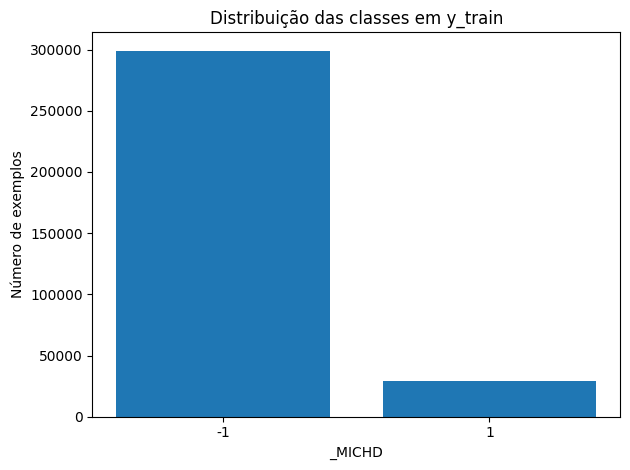

In [12]:
classes, counts = np.unique(y_train, return_counts=True)

for classe, contagem in zip(classes, counts):
    percentagem = contagem / len(y_train) * 100
    print(f"Classe {classe}: {contagem} exemplos ({percentagem:.2f}%)")

plt.bar(classes.astype(str), counts)

plt.title("Distribuição das classes em y_train")
plt.xlabel("_MICHD")
plt.ylabel("Número de exemplos")
plt.tight_layout()
plt.show()

In [13]:
def cramers_v(x, y):
    mask = ~np.isnan(x) & ~np.isnan(y)
    x = x[mask]
    y = y[mask]

    n = len(x)
    _, x_encoded = np.unique(x, return_inverse=True)
    _, y_encoded = np.unique(y, return_inverse=True)

    n_x = x_encoded.max() + 1
    n_y = y_encoded.max() + 1

    contingency_table = np.zeros((n_x, n_y), dtype=np.int64)
    np.add.at(contingency_table, (x_encoded, y_encoded), 1)

    row_totals = contingency_table.sum(axis=1)
    column_totals = contingency_table.sum(axis=0)

    expected = np.outer(row_totals, column_totals) / n

    chi2 = np.sum((contingency_table - expected) ** 2 / expected)

    denominator = n * min(n_x - 1, n_y - 1)

    if denominator == 0:
        return np.nan

    return np.sqrt(chi2 / denominator)

results = []

for i in range(x_train.shape[1]):

    x = x_train[:, i]

    valid_values = x[~np.isnan(x)]

    if len(valid_values) == 0:
        continue

    if np.unique(valid_values).size < 2:
        continue

    association = cramers_v(x, y_train)

    if not np.isnan(association):
        results.append((i, association))


results.sort(key=lambda item: item[1], reverse=True)

print("Feature | Cramér's V")

for index, value in results:
    print(f"{labels[index]} | {value:.4f}")

Feature | Cramér's V
_LLCPWT | 0.8404
_CLLCPWT | 0.7320
ASTHMAGE | 0.3859
ASACTLIM | 0.3044
ASDRVIST | 0.2667
GENHLTH | 0.2664
MAXVO2_ | 0.2663
FC60_ | 0.2649
CVDASPRN | 0.2572
ASRCHKUP | 0.2443
SEQNO | 0.2423
_PSU | 0.2423
_AGE80 | 0.2382
_AGEG5YR | 0.2372
_RFHLTH | 0.2352
LADULT | 0.2322
EMPLOY1 | 0.2314
_AGE_G | 0.2221
ASERVIST | 0.2218
BPHIGH4 | 0.2176
_RFHYPE5 | 0.2172
DIFFWALK | 0.2160
DRADVISE | 0.2102
ASYMPTOM | 0.2097
CVDSTRK3 | 0.2095
PCDMDECN | 0.2061
_AGE65YR | 0.2032
_HCVU651 | 0.1973
USEEQUIP | 0.1927
PHYSHLTH | 0.1903
CHCCOPD1 | 0.1892
_LMTSCL1 | 0.1879
VINOCRE2 | 0.1876
PNEUVAC3 | 0.1874
QLACTLM2 | 0.1866
RCSRLTN2 | 0.1853
DIABETE3 | 0.1841
_WT2RAKE | 0.1830
_LMTACT1 | 0.1806
TOLDHI2 | 0.1798
_RFCHOL | 0.1796
ASNOSLEP | 0.1756
_LMTWRK1 | 0.1741
_DRDXAR1 | 0.1684
HAVARTH3 | 0.1679
POORHLTH | 0.1664
ASINHALR | 0.1655
ASPUNSAF | 0.1632
CRGVREL1 | 0.1607
ASATTACK | 0.1606
_BMI5 | 0.1542
INTERNET | 0.1487
PA1VIGM_ | 0.1467
RDUCHART | 0.1453
ADENERGY | 0.1438
DIFFALON | 0.141

In [14]:
suspected_codes = [9, 77, 88, 99, 777, 9999, 99900]

threshold = 1.0

results = []

for i, variable in enumerate(labels):
    column = x_train[:, i]

    try:
        column = column.astype(float)
    except (ValueError, TypeError):
        continue

    valid_values = column[~np.isnan(column)]
    total = len(valid_values)

    if total == 0:
        continue

    for code in suspected_codes:
        count = np.sum(valid_values == code)

        if count > 0:
            percentage = count / total * 100

            results.append({
                "variable": variable,
                "code": code,
                "count": int(count),
                "percentage": round(percentage, 3),
                "investigate": percentage >= threshold
            })

for result in sorted(
    results,
    key=lambda x: x["percentage"],
    reverse=True
):
    if result["investigate"]:
        print(
            f"{result['variable']}: "
            f"code={result['code']}, "
            f"n_ocurrencies={result['count']}, "
            f"percentage={result['percentage']}%"
        )

ADMOVE: code=88, n_ocurrencies=13126, percentage=87.042%
ADTHINK: code=88, n_ocurrencies=12719, percentage=84.282%
ADFAIL: code=88, n_ocurrencies=12362, percentage=81.851%
_CHISPNC: code=9, n_ocurrencies=191518, percentage=80.572%
DRNK3GE5: code=88, n_ocurrencies=117010, percentage=74.565%
ADDOWN: code=88, n_ocurrencies=11102, percentage=73.387%
CHILDREN: code=88, n_ocurrencies=240617, percentage=73.329%
MENTHLTH: code=88, n_ocurrencies=224183, percentage=68.32%
ADPLEASR: code=88, n_ocurrencies=10168, percentage=67.155%
ASERVIST: code=88, n_ocurrencies=150, percentage=65.789%
ADEAT1: code=88, n_ocurrencies=9684, percentage=64.098%
PHYSHLTH: code=88, n_ocurrencies=204264, percentage=62.25%
ASDRVIST: code=88, n_ocurrencies=130, percentage=57.018%
POORHLTH: code=88, n_ocurrencies=93548, percentage=55.592%
ADSLEEP: code=88, n_ocurrencies=8016, percentage=53.012%
ADENERGY: code=88, n_ocurrencies=5802, percentage=38.381%
_DUALUSE: code=9, n_ocurrencies=123084, percentage=37.51%
ASRCHKUP: cod

## Data Pre-Processing

General health:
- GENHLTH
- PHYSHLTH
- MENTHLTH
---------------
- _RFHLTH
- POORHLTH

Health insurance:
- HLTHPLN1
---------------
- _HCVU651

Blood pressure:
- _RFHYPE5
---------------
- BPHIGH4

Cholesterol:
- _CHOLCHK
- TOLDHI2
---------------
- BLOODCHO
- CHOLCHK
- _RFCHOL

Asthma:
- _ASTHMS1
---------------
- ASTHMA3
- _LTASTH1
- _CASTHM1

Arthritis / activity limitation:
- HAVARTH3
- QLACTLM2
---------------
- _LMTACT1

Weight/height/BMI:
- _BMI5
---------------
- WEIGHT2
- HEIGHT3
- HTIN4
- WTKG3
- _BMI5CAT
- _RFBMI5

Race:
- _RACE
---------------
- _MRACE1
- _HISPANC
- _RACEG21
- _RACE_G1

Age:
- _AGEG5YR
---------------
- _AGE65YR

Income:
- INCOME2
---------------
- _INCOMG

Children:
- CHILDREN
---------------
- _CHLDCNT

Smoking:
- _SMOKER3
- USENOW3
---------------
- SMOKE100
- _RFSMOK3

Alcohol:
- DROCDY3_
- _RFBING5
- _RFDRHV5
---------------
- ALCDAY5
- DRNKANY5

Fruit:
- _FRUTSUM
---------------
- FRUITJU1
- FRUIT1
- FTJUDA1_
- FRUTDA1_
- _MISFRTN
- _FRTRESP

Vegetables:
- _VEGESUM
---------------
- FVBEANS
- FVGREEN
- FVORANG
- VEGETAB1
- BEANDAY_
- GRENDAY_
- ORNGDAY_
- VEGEDA1_
- _MISVEGN
- _VEGRESP
- _VEGLT1

Physical activity:
- EXERANY2
- PA1MIN_
- PA1VIGM_
---------------
- EXRACT11
- EXEROFT1
- EXERHMM1
- EXRACT21
- METVL11_
- METVL21_
- FC60_
- ACTIN11_
- ACTIN21_
- PAFREQ1_
- _MINAC11
- _MINAC21
- PAMISS1_
- PAMIN11_
- PAMIN21_
- PAVIG11_
- PAVIG21_
- _PACAT1
- _PA150R2
- _PA300R2
- _PAREC1
- _PASTAE1

Strength training:
- STRFREQ_
---------------
- STRENGTH
- _PASTRNG

Seatbelt use:
- SEATBELT
---------------
- _RFSEAT2


In [17]:
print(x_train.shape)

cols_to_remove = [
    # Identifiers
    "QSTVER", "QSTLANG", "FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE", "SEQNO",
    "_PSU",

    # Administrative
    "MSCODE", "FLSHTMY2", "HIVTSTD3", "_STATE",

    # Weighting variables
    "_WT2RAKE", "_STSTR", "_STRWT", "_RAWRAKE", "_DUALCOR", "_LLCPWT", "_CLLCPWT",
    "_DUALUSE",

    # Demographic variables not relevant for the prediction
    "_CRACE1", "_CPRACE", "_CHISPNC", "NUMHHOL2", "NUMPHON2", "CPDEMO1",

    # Variables only in the landline survey
    "CTELENUM", "PVTRESD1", "STATERES", "CELLFON3", "LADULT", "NUMWOMEN", "NUMMEN",
    "NUMADULT",

    # Variables only in the cell phone survey
    "CADULT", "LANDLINE", "CSTATE", "HHADULT",

    # Highly correlated with other variables (>= 95%)
    "_DRDXAR1", "HTM4", "SMOKDAY2", "_PRACE1", "MAXVO2_", "_VEGETEX", "PADUR2_", "PADUR1_",
    "_FRUITEX", "_TOTINDA", "_DRNKWEK", "_RFSEAT3", "ASTHNOW", "_LMTSCL1",
    "_AIDTST3", "_LMTWRK1", "_PAINDX1", "_PA30021", "_EDUCAG", "_FRTLT1", "_AGE80",
    "_RACEGR3", "_AGE_G",
    # "SEX",  # kept: strong predictor of MICHD

    # Missing values > 50%
    "COLGHOUS", "CTELNUM1", "CELLFON2", "PVTRESD2", "CCLGHOUS", "BPMEDS", "DIABAGE2",
    "PREGNANT", "STOPSMK2", "LASTSMK2", "AVEDRNK2", "DRNK3GE5", "MAXDRNKS", "EXEROFT2",
    "EXERHMM2", "LMTJOIN3", "ARTHDIS2", "ARTHSOCL", "JOINPAIN", "IMFVPLAC", "WHRTST10",
    "PDIABTST", "PREDIAB1", "INSULIN", "BLDSUGAR", "FEETCHK2", "DOCTDIAB", "CHKHEMO3",
    "FEETCHK", "EYEEXAM", "DIABEYE", "DIABEDU", "CAREGIV1", "CRGVREL1", "CRGVLNG1",
    "CRGVHRS1", "CRGVPRB1", "CRGVPERS", "CRGVHOUS", "CRGVMST2", "CRGVEXPT", "VIDFCLT2",
    "VIREDIF3", "VIPRFVS2", "VINOCRE2", "VIEYEXM2", "VIINSUR2", "VICTRCT4", "VIGLUMA2",
    "VIMACDG2", "CIMEMLOS", "CDHOUSE", "CDASSIST", "CDHELP", "CDSOCIAL", "CDDISCUS",
    "WTCHSALT", "LONGWTCH", "DRADVISE", "ASTHMAGE", "ASATTACK", "ASERVIST", "ASDRVIST",
    "ASRCHKUP", "ASACTLIM", "ASYMPTOM", "ASNOSLEP", "ASTHMED3", "ASINHALR", "HAREHAB1",
    "STREHAB1", "CVDASPRN", "ASPUNSAF", "RLIVPAIN", "RDUCHART", "RDUCSTRK", "ARTTODAY",
    "ARTHWGT", "ARTHEXER", "ARTHEDU", "TETANUS", "HPVADVC2", "HPVADSHT", "SHINGLE2",
    "HADMAM", "HOWLONG", "HADPAP2", "LASTPAP2", "HPVTEST", "HPLSTTST", "HADHYST2",
    "PROFEXAM", "LENGEXAM", "BLDSTOOL", "LSTBLDS3", "HADSIGM3", "HADSGCO1", "LASTSIG3",
    "PCPSAAD2", "PCPSADI1", "PCPSARE1", "PSATEST1", "PSATIME", "PCPSARS1", "PCPSADE1",
    "PCDMDECN", "SCNTMNY1", "SCNTMEL1", "SCNTPAID", "SCNTWRK1", "SCNTLPAD", "SCNTLWK1",
    "SXORIENT", "TRNSGNDR", "RCSGENDR", "RCSRLTN2", "CASTHDX2", "CASTHNO2", "EMTSUPRT",
    "LSATISFY", "ADPLEASR", "ADDOWN", "ADSLEEP", "ADENERGY", "ADEAT1", "ADFAIL", "ADTHINK",
    "ADMOVE", "MISTMNT", "ADANXEV", "PAFREQ2_", "_FLSHOT6", "_PNEUMO2",

    # Near constant features
    "_FRT16", "_VEG23",
    
    # Qualitative analysis
    "_RFHLTH", "POORHLTH", "_HCVU651", "BPHIGH4", "BLOODCHO", "CHOLCHK", "_RFCHOL",
    "ASTHMA3", "_LTASTH1", "_CASTHM1", "_LMTACT1",
    "WEIGHT2", "HEIGHT3", "HTIN4", "WTKG3", "_BMI5CAT", "_RFBMI5",
    "_MRACE1", "_HISPANC", "_RACEG21", "_RACE_G1", "_AGE65YR", "_INCOMG", "_CHLDCNT",
    "SMOKE100", "_RFSMOK3", "ALCDAY5", "DRNKANY5",
    "FRUITJU1", "FRUIT1", "FTJUDA1_", "FRUTDA1_", "_MISFRTN", "_FRTRESP",
    "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1", "BEANDAY_", "GRENDAY_", "ORNGDAY_",
    "VEGEDA1_", "_MISVEGN", "_VEGRESP", "_VEGLT1",
    "EXRACT11", "EXEROFT1", "EXERHMM1", "EXRACT21", "METVL11_", "METVL21_", "FC60_",
    "ACTIN11_", "ACTIN21_", "PAFREQ1_", "_MINAC11", "_MINAC21", "PAMISS1_", "PAMIN11_",
    "PAMIN21_", "PAVIG11_", "PAVIG21_", "_PACAT1", "_PA150R2", "_PA300R2", "_PAREC1",
    "_PASTAE1", "STRENGTH", "_PASTRNG", "_RFSEAT2",
]

print("Features to remove:", [c for c in cols_to_remove if c in labels])

cols_idx = [labels.index(col) for col in cols_to_remove if col in labels]

x_train = np.delete(x_train, cols_idx, axis=1)

labels = [col for col in labels if col not in cols_to_remove]

print("x_train:", x_train.shape)
print("labels:", len(labels))
print(labels)


(328135, 123)
Features to remove: ['_RFHLTH', 'POORHLTH', '_HCVU651', 'BPHIGH4', 'BLOODCHO', 'CHOLCHK', '_RFCHOL', 'ASTHMA3', '_LTASTH1', '_CASTHM1', '_LMTACT1', 'WEIGHT2', 'HEIGHT3', 'HTIN4', 'WTKG3', '_BMI5CAT', '_RFBMI5', '_MRACE1', '_HISPANC', '_RACEG21', '_RACE_G1', '_AGE65YR', '_INCOMG', '_CHLDCNT', 'SMOKE100', '_RFSMOK3', 'ALCDAY5', 'DRNKANY5', 'FRUITJU1', 'FRUIT1', 'FTJUDA1_', 'FRUTDA1_', '_MISFRTN', '_FRTRESP', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'BEANDAY_', 'GRENDAY_', 'ORNGDAY_', 'VEGEDA1_', '_MISVEGN', '_VEGRESP', '_VEGLT1', 'EXRACT11', 'EXEROFT1', 'EXERHMM1', 'EXRACT21', 'METVL11_', 'METVL21_', 'FC60_', 'ACTIN11_', 'ACTIN21_', 'PAFREQ1_', '_MINAC11', '_MINAC21', 'PAMISS1_', 'PAMIN11_', 'PAMIN21_', 'PAVIG11_', 'PAVIG21_', '_PACAT1', '_PA150R2', '_PA300R2', '_PAREC1', '_PASTAE1', 'STRENGTH', '_PASTRNG', '_RFSEAT2']
x_train: (328135, 53)
labels: 53
['GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'TOLDHI2', 'CVDSTRK3', 'CHCSCNCR', 'C

In [16]:
zero_codes = {
    "CHILDREN": [88], "MENTHLTH": [88], "PHYSHLTH": [88],
}

missing_codes = {
    # 7 = Don't know, 9 = Refused
    "GENHLTH": [7, 9], "HLTHPLN1": [7, 9], "PERSDOC2": [7, 9], "MEDCOST": [7, 9],
    "CHECKUP1": [7, 9], "TOLDHI2": [7, 9], "CVDSTRK3": [7, 9], "CHCSCNCR": [7, 9],
    "CHCOCNCR": [7, 9], "CHCCOPD1": [7, 9], "HAVARTH3": [7, 9], "ADDEPEV2": [7, 9],
    "CHCKIDNY": [7, 9], "DIABETE3": [7, 9], "RENTHOM1": [7, 9], "VETERAN3": [7, 9],
    "INTERNET": [7, 9], "QLACTLM2": [7, 9], "USEEQUIP": [7, 9], "BLIND": [7, 9],
    "DECIDE": [7, 9], "DIFFWALK": [7, 9], "DIFFDRES": [7, 9], "DIFFALON": [7, 9],
    "USENOW3": [7, 9], "EXERANY2": [7, 9], "FLUSHOT6": [7, 9], "PNEUVAC3": [7, 9],
    "HIVTST6": [7, 9],
    "SEATBELT": [7, 8, 9],  # 8 = Never drive or ride in a car

    # 9 = Refused / Don't know / Missing
    "MARITAL": [9], "EDUCA": [9], "EMPLOY1": [9],
    "_RFHYPE5": [9], "_CHOLCHK": [9], "_ASTHMS1": [9], "_RACE": [9],
    "_SMOKER3": [9], "_RFBING5": [9], "_RFDRHV5": [9],

    # 77 = Don't know, 99 = Refused
    "PHYSHLTH": [77, 99], "MENTHLTH": [77, 99], "INCOME2": [77, 99],
    "CHILDREN": [99],

    # Other codes
    "_AGEG5YR": [14],     # Don't know / Refused / Missing
    "DROCDY3_": [900],    # Don't know / Refused / Missing
    "STRFREQ_": [99900],  # Don't know / Refused / Missing
}

for variable, codes in zero_codes.items():

    idx = labels.index(variable)
    column = x_train[:, idx].astype(float)

    for code in codes:
        column[column == code] = 0

    x_train[:, idx] = column

for variable, codes in missing_codes.items():

    idx = labels.index(variable)
    column = x_train[:, idx].astype(float)

    for code in codes:
        column[column == code] = np.nan

    x_train[:, idx] = column



In [18]:
features = headers[1:]

numerical_cols = [
    "PHYSHLTH", "MENTHLTH", "CHILDREN", "_BMI5", "DROCDY3_",
    "_FRUTSUM", "_VEGESUM", "STRFREQ_", "PA1MIN_", "PA1VIGM_",
]

ordinal_cols = [
    "GENHLTH", "CHECKUP1", "EDUCA", "INCOME2", "_AGEG5YR",
    "USENOW3", "SEATBELT", "_SMOKER3", "_CHOLCHK", "_ASTHMS1",
]

nominal_cols = [
    # Binary (yes/no)
    "HLTHPLN1", "MEDCOST", "TOLDHI2", "CVDSTRK3", "CHCSCNCR", "CHCOCNCR",
    "CHCCOPD1", "HAVARTH3", "ADDEPEV2", "CHCKIDNY", "SEX", "VETERAN3",
    "INTERNET", "QLACTLM2", "USEEQUIP", "BLIND", "DECIDE", "DIFFWALK",
    "DIFFDRES", "DIFFALON", "EXERANY2", "FLUSHOT6", "PNEUVAC3", "HIVTST6",
    "_RFHYPE5", "_RFBING5", "_RFDRHV5",

    # Multi-class
    "PERSDOC2", "DIABETE3", "MARITAL", "RENTHOM1", "EMPLOY1", "_RACE",
]
